# Waste Material Recognition — Optimized Local/Colab Notebook

**Classes:** Glass, Paper, Cardboard, Plastic, Metal, Trash

This notebook is adapted from the supplied project notebook. It preserves the three-model comparison (baseline CNN, improved CNN, MobileNetV2), validation-based model selection, evaluation plots, confusion matrix, classification report, and saved-model prediction workflow.

**Run cells from top to bottom.** The notebook downloads the resized TrashNet dataset if it is missing. No accuracy or other result is pre-filled; all results must come from an actual run.

**Performance settings:** 160 × 160 images, batch size 16, and at most 8 epochs per model. Early stopping can finish sooner. These settings reduce resource use compared with the original 160 × 160 / batch 64 / 15-epoch configuration, but may affect accuracy. Set `IMAGE_SIZE`, `BATCH_SIZE`, or `EPOCHS` higher if your hardware permits.


## 1. Introduction

Waste segregation is an important step in recycling because mixing materials can contaminate otherwise recyclable waste. This project uses computer vision to recognise the type of waste in an image and assign one of six labels: glass, paper, cardboard, plastic, metal, or trash.

An image classifier can support smart waste bins, material-recovery facilities, educational tools, and decision support for manual sorting. Its output should assist people and systems; it should not be treated as a safety decision for hazardous waste.

## 2. Problem Statement

Manual sorting is repetitive, can be inconsistent, and does not scale easily. The task is to build and evaluate an image-classification system that receives a single waste-item image and predicts its material category.

The system must be evaluated fairly: training data are used to fit model parameters, validation data are used to choose the model, and the test set remains separate until final reporting.

## 3. Objective

The objective is to develop a reproducible TensorFlow/Keras pipeline that:

- downloads and verifies the official TrashNet resized dataset;
- explores the actual image files and class balance;
- creates stratified 70% / 15% / 15% train, validation, and test partitions;
- compares a baseline CNN, an improved CNN, and MobileNetV2 transfer learning;
- selects a model using validation performance and reports final test metrics; and
- saves the selected model and class mapping for future predictions.

## 4. Dataset Description

TrashNet was collected by Gary Thung and Mindy Yang for a Stanford CS229 project. The supplied official README describes six classes—glass, paper, cardboard, plastic, metal, and trash—photographed on a white posterboard under sunlight and/or room lighting. The README reports that the resized version contains 2,527 images at 512 × 384 pixels.

This notebook downloads the official author-published `dataset-resized.zip` archive. The actual locally downloaded image count and counts per class are computed below instead of being manually entered.

**Citation:** Thung, G., & Yang, M. (2016). *Classification of Trash for Recyclability Status*. TrashNet dataset and project repository.

## 5. Import Libraries

The following cell loads the packages used for data handling, visualization, splitting, evaluation, and TensorFlow/Keras modelling. A fixed random seed supports repeatable splits and training behaviour where possible.

In [1]:
# Core Python libraries
import os
import json
import random
import shutil
import time
import zipfile
from pathlib import Path

# Data, images, plots, and metrics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_recall_fscore_support
)

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

sns.set_theme(style="whitegrid")
print(f"Python version: {os.sys.version.split()[0]}")
print(f"TensorFlow version: {tf.__version__}")
print("Visible GPU(s):", tf.config.list_physical_devices("GPU"))


Python version: 3.11.9
TensorFlow version: 2.19.1
Visible GPU(s): []


## 6. Download / Load Dataset

The official README links to the author-published TrashNet dataset on Hugging Face. Only the resized archive is downloaded because it is suitable for this classification project and is substantially smaller than the original-resolution archive.

The download and extraction are idempotent: rerunning the cell reuses a verified existing dataset folder. Archive paths are checked before extraction.

In [2]:
# Dataset paths are relative to the folder from which this notebook is run.
# Run the notebook from the project folder for the recommended folder layout.
DATASET_URL = (
    "https://huggingface.co/datasets/garythung/trashnet/"
    "resolve/main/dataset-resized.zip?download=true"
)

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
ZIP_PATH = DATA_DIR / "dataset-resized.zip"
EXTRACT_DIR = DATA_DIR / "raw"
DATASET_DIR = EXTRACT_DIR / "dataset-resized"
MODEL_DIR = PROJECT_DIR / "models"

EXPECTED_CLASSES = {"glass", "paper", "cardboard", "plastic", "metal", "trash"}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

DATA_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

def download_file(url, destination, chunk_size=1024 * 1024):
    """Stream a download to disk and show progress when content length is known."""
    temporary_path = destination.with_suffix(destination.suffix + ".part")
    with requests.get(url, stream=True, timeout=60) as response:
        response.raise_for_status()
        total = int(response.headers.get("content-length", 0))
        downloaded = 0
        with open(temporary_path, "wb") as file:
            for chunk in response.iter_content(chunk_size=chunk_size):
                if chunk:
                    file.write(chunk)
                    downloaded += len(chunk)
                    if total:
                        print(f"\rDownloading: {100 * downloaded / total:6.2f}%", end="")
    temporary_path.replace(destination)
    print()

def safe_extract(zip_file, destination):
    """Reject ZIP paths that would extract outside the destination directory."""
    destination.mkdir(parents=True, exist_ok=True)
    destination_resolved = destination.resolve()
    with zipfile.ZipFile(zip_file, "r") as archive:
        for member in archive.infolist():
            member_path = (destination_resolved / member.filename).resolve()
            if member_path != destination_resolved and destination_resolved not in member_path.parents:
                raise RuntimeError(f"Unsafe ZIP member: {member.filename}")
        archive.extractall(destination)

if not ZIP_PATH.exists():
    print("Downloading the resized TrashNet dataset...")
    download_file(DATASET_URL, ZIP_PATH)
else:
    print(f"Using existing archive: {ZIP_PATH}")

if not DATASET_DIR.exists():
    print("Extracting dataset...")
    safe_extract(ZIP_PATH, EXTRACT_DIR)
else:
    print(f"Using extracted dataset: {DATASET_DIR}")

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Expected class folders at {DATASET_DIR}. "
        "Check the ZIP's extracted folder structure."
    )
print(f"Dataset directory: {DATASET_DIR}")


Downloading: 100.00%
Extracting dataset...
Dataset directory: c:\Persona Drive\waste_material_recognition_project\data\raw\dataset-resized


## 7. Exploratory Data Analysis

This section validates the actual class-folder structure, counts the image files, visualizes class distribution, and shows sample images. The results printed here are the values to use in the report.

A small class has fewer examples from which to learn. This matters particularly for `trash` if it is confirmed by the computed table to be the smallest class; later, stratification and per-class metrics help prevent overall accuracy from hiding weak minority-class performance.

In [3]:
# Verify the folders and create one manifest row per image.
class_dirs = sorted(path for path in DATASET_DIR.iterdir() if path.is_dir())
actual_classes = [path.name.lower() for path in class_dirs]

if set(actual_classes) != EXPECTED_CLASSES:
    raise ValueError(
        f"Unexpected folders. Expected {sorted(EXPECTED_CLASSES)}, found {sorted(actual_classes)}"
    )

records = []
for class_dir in class_dirs:
    for image_path in sorted(class_dir.rglob("*")):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            records.append({"filepath": str(image_path), "class_name": class_dir.name.lower()})

manifest = pd.DataFrame(records)
if manifest.empty:
    raise RuntimeError("No supported image files were found in the dataset.")

class_names = sorted(manifest["class_name"].unique().tolist())
class_to_index = {name: index for index, name in enumerate(class_names)}
index_to_class = {index: name for name, index in class_to_index.items()}
manifest["label"] = manifest["class_name"].map(class_to_index)

class_counts = (
    manifest.groupby("class_name", as_index=False)
    .size()
    .rename(columns={"size": "image_count"})
    .sort_values("class_name")
    .reset_index(drop=True)
)

print("Folder structure:")
for class_dir in class_dirs:
    print(f"├── {class_dir.name}/")

print(f"\nNumber of classes: {len(class_names)}")
print(f"Total images found: {len(manifest)}")
display(class_counts)

with open(PROJECT_DIR / "class_mapping.json", "w") as file:
    json.dump(class_to_index, file, indent=2)
print(f"Saved class mapping to: {PROJECT_DIR / 'class_mapping.json'}")

Folder structure:
├── cardboard/
├── glass/
├── metal/
├── paper/
├── plastic/
├── trash/

Number of classes: 6
Total images found: 2527


,class_name,image_count
0,cardboard,403
1,glass,501
2,metal,410
3,paper,594
4,plastic,482
5,trash,137


Saved class mapping to: c:\Persona Drive\waste_material_recognition_project\class_mapping.json


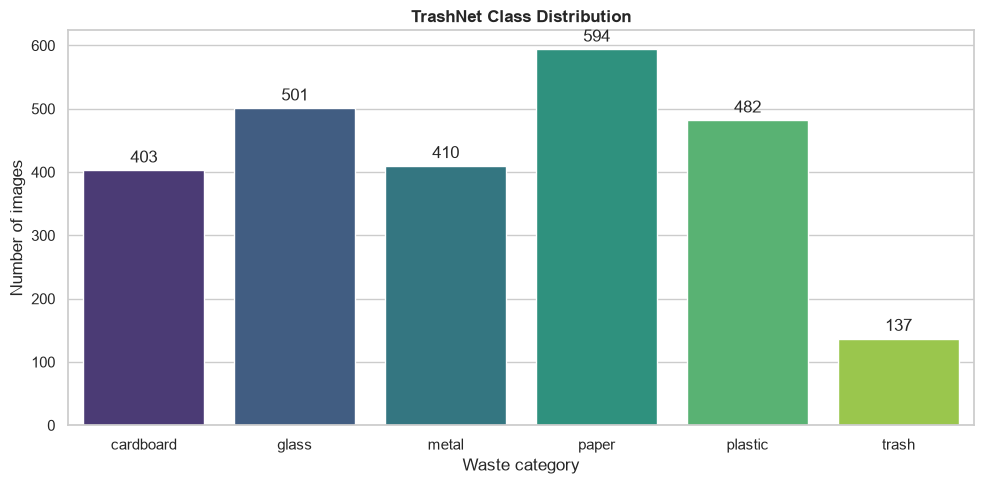

Smallest class: trash (137 images)
Largest class: paper (594 images)
Use stratified splits and per-class precision, recall, and F1-score in later evaluation.


In [4]:
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=class_counts, x="class_name", y="image_count",
    hue="class_name", legend=False, palette="viridis"
)
plt.title("TrashNet Class Distribution", weight="bold")
plt.xlabel("Waste category")
plt.ylabel("Number of images")
for container in ax.containers:
    ax.bar_label(container, padding=3)
plt.tight_layout()
plt.show()

smallest = class_counts.loc[class_counts["image_count"].idxmin()]
largest = class_counts.loc[class_counts["image_count"].idxmax()]
print(f"Smallest class: {smallest.class_name} ({smallest.image_count} images)")
print(f"Largest class: {largest.class_name} ({largest.image_count} images)")
print("Use stratified splits and per-class precision, recall, and F1-score in later evaluation.")

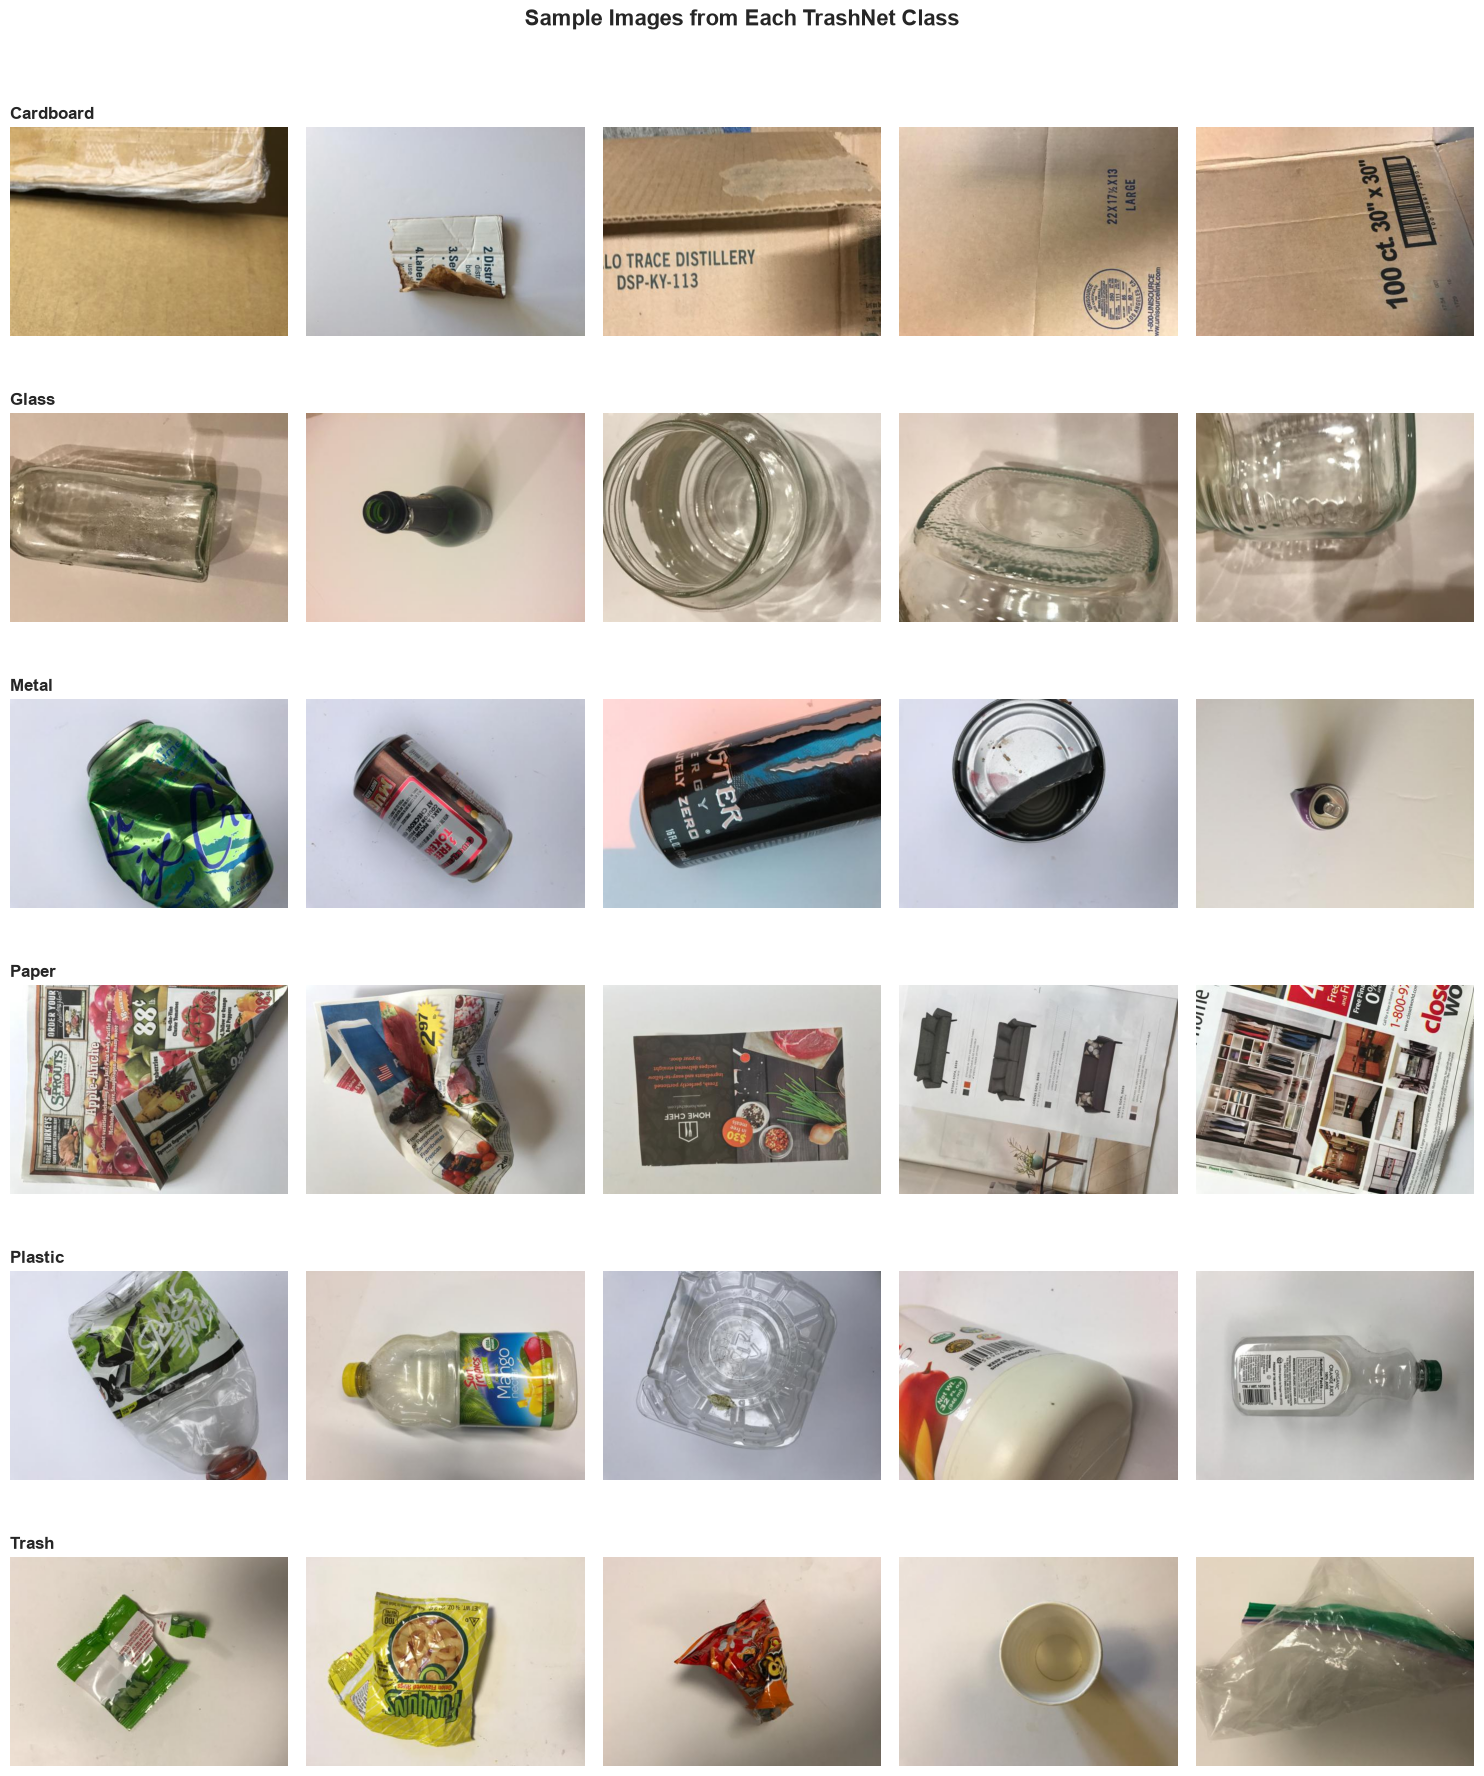

In [5]:
# Display reproducible random samples from every verified class.
samples_per_class = 5
fig, axes = plt.subplots(len(class_names), samples_per_class, figsize=(15, 3 * len(class_names)))

for row, class_name in enumerate(class_names):
    paths = manifest.loc[manifest["class_name"] == class_name, "filepath"].tolist()
    selected = random.Random(SEED + row).sample(paths, k=min(samples_per_class, len(paths)))

    for col, ax in enumerate(axes[row]):
        ax.axis("off")
        if col < len(selected):
            with Image.open(selected[col]) as image:
                ax.imshow(image.convert("RGB"))
            if col == 0:
                ax.set_title(class_name.capitalize(), loc="left", weight="bold")

plt.suptitle("Sample Images from Each TrashNet Class", y=1.01, weight="bold", fontsize=16)
plt.tight_layout()
plt.show()

In [6]:
# Inspect the original dimensions of a random, bounded sample of images.
inspect_paths = manifest["filepath"].sample(n=min(200, len(manifest)), random_state=SEED)
dimensions = []
for file_path in inspect_paths:
    with Image.open(file_path) as image:
        dimensions.append(image.size)  # (width, height)

dimensions_df = pd.DataFrame(dimensions, columns=["width", "height"])
display(dimensions_df.describe().round(2))
print("Image dimensions are inspected before resizing. All model inputs will later be resized to 224 × 224.")

,width,height
count,200.0,200.0
mean,512.0,384.0
std,0.0,0.0
min,512.0,384.0
25%,512.0,384.0
50%,512.0,384.0
75%,512.0,384.0
max,512.0,384.0


Image dimensions are inspected before resizing. All model inputs will later be resized to 224 × 224.


## 8. Data Preprocessing

Every image is decoded as RGB, resized to 160 × 160 pixels, converted to `float32`, and normalized from the integer range 0–255 to the floating-point range 0–1. Labels are encoded using the saved class mapping.

Resizing gives every model a consistent input shape. Normalization makes optimization more stable, while the original file paths remain available for traceability and sample predictions.

In [7]:
# Lower image size and batch size are friendlier to typical student laptops.
IMAGE_SIZE = (160, 160)
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

def load_and_preprocess_image(filepath, label):
    """Read, decode, resize, and normalize one image."""
    image_bytes = tf.io.read_file(filepath)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE, antialias=True)
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.cast(label, tf.int32)

def make_dataset(dataframe, training=False):
    """Create a streaming dataset; avoid caching the entire image set in RAM."""
    dataset = tf.data.Dataset.from_tensor_slices(
        (dataframe["filepath"].values, dataframe["label"].values)
    )
    dataset = dataset.map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(dataframe), 1000),
            seed=SEED,
            reshuffle_each_iteration=True
        )
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

example_image, example_label = next(iter(make_dataset(manifest.head(1))))
print("Preprocessed image batch shape:", example_image.shape)
print("Pixel range:", float(tf.reduce_min(example_image)), "to", float(tf.reduce_max(example_image)))
print("Encoded label:", int(example_label[0]))


Preprocessed image batch shape: (1, 160, 160, 3)
Pixel range: 0.016512371599674225 to 0.9603418111801147
Encoded label: 0


## 9. Data Augmentation

Augmentation creates plausible variations of **training images only**. It is placed inside the improved CNN and transfer-learning models, where Keras automatically applies it only when `training=True`.

Validation and test images are never augmented. This preserves fair, realistic evaluation.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.11673711..1.0000001].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.10901487..1.0006722].


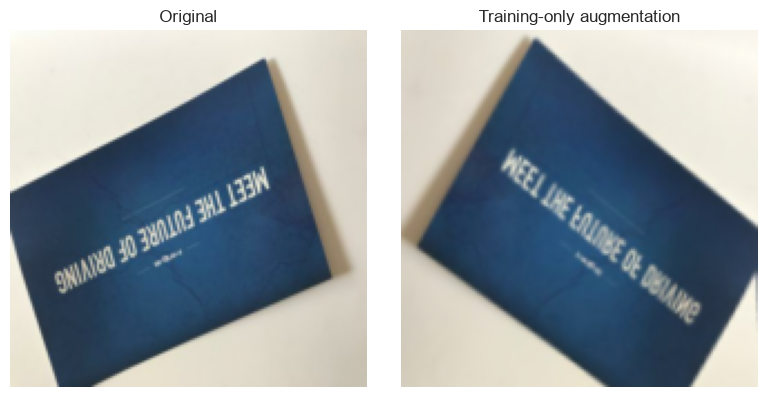

In [8]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomRotation(0.08, seed=SEED),
        layers.RandomZoom(0.10, seed=SEED),
        layers.RandomContrast(0.10, seed=SEED),
    ],
    name="training_augmentation",
)

# Visual check only; this does not alter the stored images or test data.
image_batch, _ = next(iter(make_dataset(manifest.sample(n=1, random_state=SEED))))
augmented_batch = data_augmentation(image_batch, training=True)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(image_batch[0])
axes[0].set_title("Original")
axes[1].imshow(augmented_batch[0])
axes[1].set_title("Training-only augmentation")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 10. Train / Validation / Test Split

The dataset is split with stratification: 70% training, 15% validation, and 15% test. Stratification preserves each class's proportion as closely as possible in every partition.

The test set is created once, stored separately, and never used by callbacks, early stopping, or model-selection decisions. The validation set determines the selected architecture.

In [9]:
train_df, temporary_df = train_test_split(
    manifest, test_size=0.30, random_state=SEED, stratify=manifest["label"]
)
validation_df, test_df = train_test_split(
    temporary_df, test_size=0.50, random_state=SEED, stratify=temporary_df["label"]
)

train_df = train_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

assert set(train_df["filepath"]).isdisjoint(test_df["filepath"])
assert set(validation_df["filepath"]).isdisjoint(test_df["filepath"])
assert set(train_df["filepath"]).isdisjoint(validation_df["filepath"])

split_summary = pd.DataFrame(
    {
        "Split": ["Train", "Validation", "Test"],
        "Images": [len(train_df), len(validation_df), len(test_df)],
        "Percentage": [100 * len(train_df) / len(manifest), 100 * len(validation_df) / len(manifest), 100 * len(test_df) / len(manifest)],
    }
)
split_summary["Percentage"] = split_summary["Percentage"].round(2)
display(split_summary)

train_ds = make_dataset(train_df, training=True)
validation_ds = make_dataset(validation_df)
test_ds = make_dataset(test_df)
print("Train, validation, and test datasets are ready.")

,Split,Images,Percentage
0,Train,1768,69.96
1,Validation,379,15.00
2,Test,380,15.04


Train, validation, and test datasets are ready.


## 11. Model 1 — Baseline CNN

This baseline convolutional neural network is trained from scratch. It establishes a simple reference performance using convolution, max pooling, global average pooling, and a softmax classifier.

In [10]:
NUM_CLASSES = len(class_names)

def compile_model(model):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )
    return model

def build_baseline_cnn():
    inputs = keras.Input(shape=(*IMAGE_SIZE, 3), name="image")
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(inputs)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(128, 3, activation="relu", padding="same")(x)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="class_probabilities")(x)
    return compile_model(keras.Model(inputs, outputs, name="baseline_cnn"))

baseline_cnn = build_baseline_cnn()
baseline_cnn.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,022 (367.27 KB)

 Trainable params: 94,022 (367.27 KB)

 Non-trainable params: 0 (0.00 B)

## 12. Model 2 — Improved CNN

The improved CNN uses training-only augmentation, batch normalization, dropout, and global average pooling. These additions aim to improve generalization and reduce overfitting compared with the baseline model.

In [11]:
def conv_block(x, filters, dropout_rate):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    return layers.Dropout(dropout_rate)(x)

def build_improved_cnn():
    inputs = keras.Input(shape=(*IMAGE_SIZE, 3), name="image")
    x = data_augmentation(inputs)
    x = conv_block(x, 32, 0.15)
    x = conv_block(x, 64, 0.20)
    x = conv_block(x, 128, 0.30)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.35)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="class_probabilities")(x)
    return compile_model(keras.Model(inputs, outputs, name="improved_cnn"))

improved_cnn = build_improved_cnn()
improved_cnn.summary()

Model: "improved_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ training_augmentation           │ (None, 160, 160, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 160, 160, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 160, 160, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 80, 80, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 80, 80, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 40, 40, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 40, 40, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 40, 40, 128)    │       147,45

 Total params: 305,638 (1.17 MB)

 Trainable params: 304,742 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

## 13. Model 3 — Transfer Learning with MobileNetV2

MobileNetV2 is a compact image model pretrained on ImageNet. The convolutional base is initially frozen, while a new classification head learns the TrashNet labels. This is generally practical on a Colab GPU and is evaluated rather than assumed to be superior.

In [12]:
def build_mobilenetv2():
    inputs = keras.Input(shape=(*IMAGE_SIZE, 3), name="image")
    x = data_augmentation(inputs)
    # The pipeline normalizes to [0, 1]. MobileNetV2 expects values in [-1, 1].
    x = layers.Rescaling(scale=2.0, offset=-1.0, name="mobilenetv2_preprocessing")(x)

    base_model = keras.applications.MobileNetV2(
        include_top=False, weights="imagenet", input_shape=(*IMAGE_SIZE, 3)
    )
    base_model.trainable = False
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.30)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="class_probabilities")(x)

    model = keras.Model(inputs, outputs, name="mobilenetv2_transfer")
    return compile_model(model)

mobilenetv2_transfer = build_mobilenetv2()
mobilenetv2_transfer.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ training_augmentation           │ (None, 160, 160, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_preprocessing       │ (None, 160, 160, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 14. Model Training

All models use the same training and validation partitions. Early stopping restores the best validation checkpoint, model checkpoints retain the best weights on disk, and learning-rate reduction responds to stalled validation loss.

Training time and history are captured automatically. Do not interpret the test set during this stage.

In [13]:
# These are maximum epochs; EarlyStopping may stop a model sooner.
EPOCHS = 8

def make_callbacks(model_name):
    checkpoint_path = MODEL_DIR / f"{model_name}_best.keras"
    return [
        keras.callbacks.ModelCheckpoint(
            filepath=checkpoint_path, monitor="val_accuracy", mode="max",
            save_best_only=True, verbose=1
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=3, restore_best_weights=True, verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1
        ),
    ]

def train_model(model, model_name):
    start = time.perf_counter()
    history = model.fit(
        train_ds, validation_data=validation_ds, epochs=EPOCHS,
        callbacks=make_callbacks(model.name), verbose=1
    )
    duration = time.perf_counter() - start
    return history, duration

models = {
    "Baseline CNN": baseline_cnn,
    "Improved CNN": improved_cnn,
    "MobileNetV2 Transfer": mobilenetv2_transfer,
}

histories = {}
training_times = {}

for model_name, model in models.items():
    print(f"\n{'=' * 18} Training {model_name} {'=' * 18}")
    histories[model_name], training_times[model_name] = train_model(model, model_name)

print("\nCandidate-model training complete. The test set has not been used.")



================== Training Baseline CNN ==================
Epoch 1/8


c:\Persona Drive\waste_material_recognition_project\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 256ms/step - accuracy: 0.2670 - loss: 1.6622
Epoch 1: val_accuracy improved from None to 0.35884, saving model to c:\Persona Drive\waste_material_recognition_project\models\baseline_cnn_best.keras

Epoch 1: finished saving model to c:\Persona Drive\waste_material_recognition_project\models\baseline_cnn_best.keras
111/111 ━━━━━━━━━━━━━━━━━━━━ 33s 275ms/step - accuracy: 0.2670 - loss: 1.6622 - val_accuracy: 0.3588 - val_loss: 1.5783 - learning_rate: 0.0010
Epoch 2/8
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step - accuracy: 0.3801 - loss: 1.4957
Epoch 2: val_accuracy improved from 0.35884 to 0.41425, saving model to c:\Persona Drive\waste_material_recognition_project\models\baseline_cnn_best.keras

Epoch 2: finished saving model to c:\Persona Drive\waste_material_recognition_project\models\baseline_cnn_best.keras
111/111 ━━━━━━━━━━━━━━━━━━━━ 27s 230ms/step - accuracy: 0.3801 - loss: 1.4957 - val_accuracy: 0.4142 - val_loss: 1.4434 - learning_rate: 0.0010
Epoch

## 15. Model Performance Comparison

Training and validation curves reveal learning progress and potential overfitting. Candidate selection is based on the best validation accuracy, not on the test set.

The held-out test evaluation occurs only after this selection, so it cannot influence training choices.

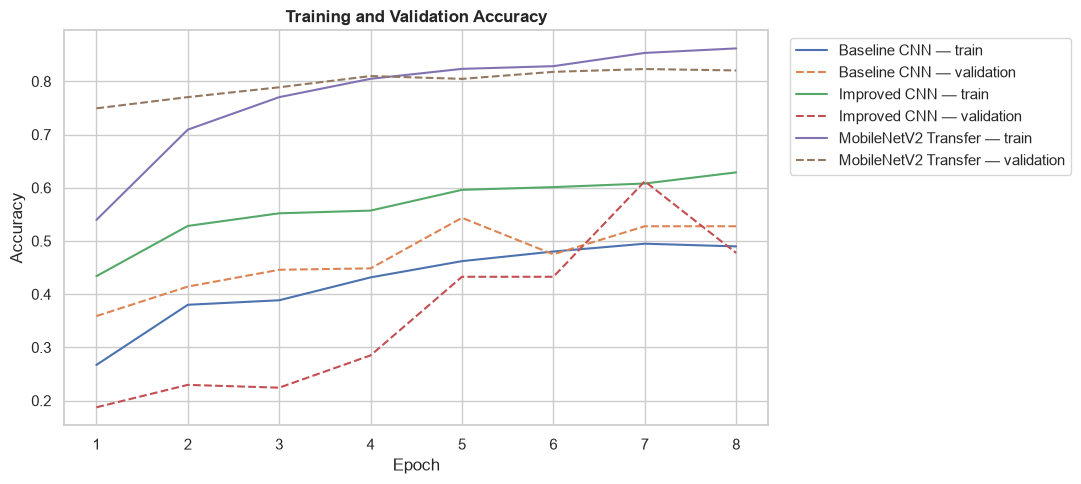

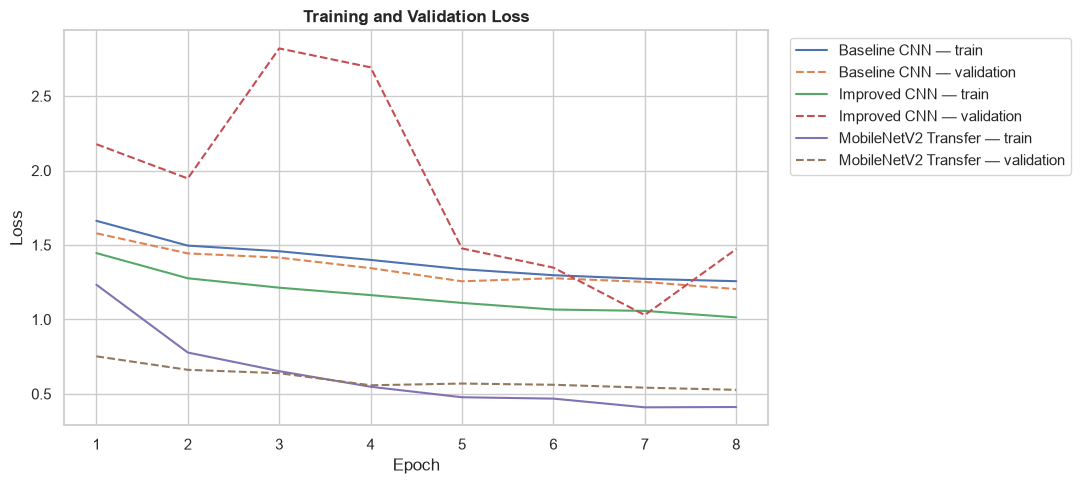

In [14]:
def plot_histories(histories, metric, title, ylabel):
    plt.figure(figsize=(11, 5))
    for name, history in histories.items():
        values = history.history[metric]
        validation_values = history.history[f"val_{metric}"]
        epochs = range(1, len(values) + 1)
        plt.plot(epochs, values, label=f"{name} — train")
        plt.plot(epochs, validation_values, linestyle="--", label=f"{name} — validation")
    plt.title(title, weight="bold")
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

plot_histories(histories, "accuracy", "Training and Validation Accuracy", "Accuracy")
plot_histories(histories, "loss", "Training and Validation Loss", "Loss")

,Model,Parameters,Best Validation Accuracy,Best Validation Loss,Training Time (min)
0,MobileNetV2 Transfer,2265670,0.8232,0.5272,5.41
1,Improved CNN,305638,0.6121,1.0296,30.16
2,Baseline CNN,94022,0.5435,1.2036,3.81


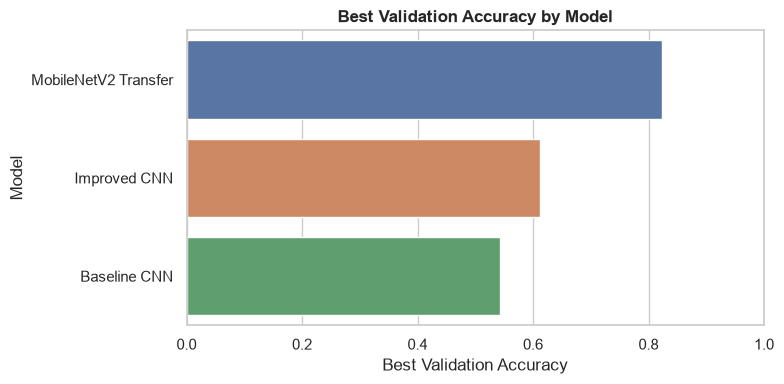

In [15]:
comparison_rows = []
for name, model in models.items():
    history = histories[name].history
    comparison_rows.append({
        "Model": name,
        "Parameters": model.count_params(),
        "Best Validation Accuracy": max(history["val_accuracy"]),
        "Best Validation Loss": min(history["val_loss"]),
        "Training Time (min)": training_times[name] / 60,
    })

validation_comparison = pd.DataFrame(comparison_rows).sort_values(
    "Best Validation Accuracy", ascending=False
).reset_index(drop=True)
display(validation_comparison.style.format({
    "Best Validation Accuracy": "{:.4f}",
    "Best Validation Loss": "{:.4f}",
    "Training Time (min)": "{:.2f}",
}))

plt.figure(figsize=(8, 4))
sns.barplot(data=validation_comparison, x="Best Validation Accuracy", y="Model", hue="Model", legend=False)
plt.xlim(0, 1)
plt.title("Best Validation Accuracy by Model", weight="bold")
plt.tight_layout()
plt.show()

## 16. Best Model Selection

The model with the highest validation accuracy is selected automatically. Validation performance is used because the test partition must remain an unbiased final holdout.

If validation loss rises while training loss continues to fall, that is evidence of possible overfitting; inspect the curves above before discussing it in the report.

In [16]:
best_model_name = validation_comparison.iloc[0]["Model"]
best_model = models[best_model_name]
best_checkpoint = MODEL_DIR / f"{best_model.name}_best.keras"

# Reload exactly the checkpoint with the best validation accuracy.
best_model = keras.models.load_model(best_checkpoint)

print(f"Selected model: {best_model_name}")
print(f"Selection criterion: highest validation accuracy = {validation_comparison.iloc[0]['Best Validation Accuracy']:.4f}")
print(f"Loaded best validation checkpoint: {best_checkpoint}")

Selected model: MobileNetV2 Transfer
Selection criterion: highest validation accuracy = 0.8232
Loaded best validation checkpoint: c:\Persona Drive\waste_material_recognition_project\models\mobilenetv2_transfer_best.keras


## 17. Final Model Training / Fine-Tuning

The selected checkpoint is already the best version found during validation-guided training. The following cell saves it as the final reusable model together with the class mapping.

Optional fine-tuning is deliberately not performed automatically: it requires a new validation-guided experiment. This avoids using the test set to make training decisions.

In [17]:
FINAL_MODEL_PATH = MODEL_DIR / "best_waste_classifier.keras"
FINAL_MAPPING_PATH = MODEL_DIR / "class_mapping.json"

shutil.copy2(best_checkpoint, FINAL_MODEL_PATH)
with open(FINAL_MAPPING_PATH, "w") as file:
    json.dump(class_to_index, file, indent=2)

print(f"Final model saved to: {FINAL_MODEL_PATH}")
print(f"Class mapping saved to: {FINAL_MAPPING_PATH}")

Final model saved to: c:\Persona Drive\waste_material_recognition_project\models\best_waste_classifier.keras
Class mapping saved to: c:\Persona Drive\waste_material_recognition_project\models\class_mapping.json


## 18. Final Test Evaluation

The test set is evaluated only now, after model selection and saving are complete. Test loss and accuracy are obtained from actual predictions; no metric is entered manually.

Do not rerun model selection based on these values. The test set is a final estimate of generalization performance.

In [18]:
test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=1)
probabilities = best_model.predict(test_ds, verbose=1)
y_pred = probabilities.argmax(axis=1)
y_true = test_df["label"].to_numpy()

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="weighted", zero_division=0
)

final_metrics = pd.DataFrame([
    {
        "Selected Model": best_model_name,
        "Test Loss": test_loss,
        "Test Accuracy": test_accuracy,
        "Weighted Precision": precision,
        "Weighted Recall": recall,
        "Weighted F1-score": f1,
    }
])
display(final_metrics.style.format({column: "{:.4f}" for column in final_metrics.columns if column != "Selected Model"}))

24/24 ━━━━━━━━━━━━━━━━━━━━ 11s 310ms/step - accuracy: 0.8105 - loss: 0.5558
24/24 ━━━━━━━━━━━━━━━━━━━━ 9s 345ms/step


,Selected Model,Test Loss,Test Accuracy,Weighted Precision,Weighted Recall,Weighted F1-score
0,MobileNetV2 Transfer,0.5558,0.8105,0.8135,0.8105,0.8048


### Final Candidate Test Comparison
+
+The following comparison evaluates every already-trained candidate on the same untouched test set **after** validation-based selection. These values are for transparent final reporting only; they must not be used to tune models or revise the selection procedure.

,Model,Parameters,Best Validation Accuracy,Best Validation Loss,Training Time (min),Test Accuracy,Test Loss
0,MobileNetV2 Transfer,2265670,0.8232,0.5272,5.41,0.8132,0.5317
1,Improved CNN,305638,0.6121,1.0296,30.16,0.5711,1.1109
2,Baseline CNN,94022,0.5435,1.2036,3.81,0.4868,1.2836


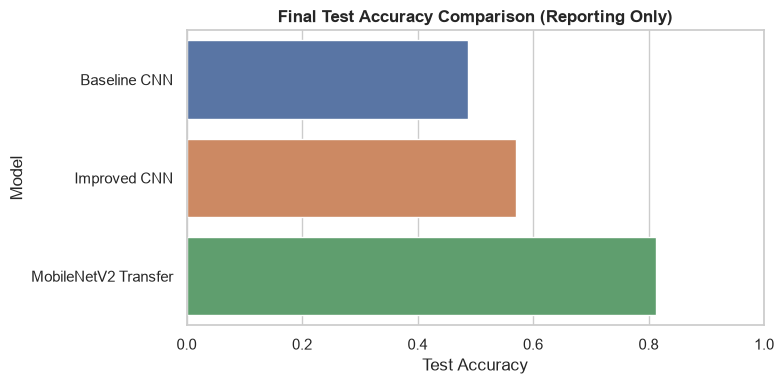

In [19]:
test_comparison_rows = []
for model_name, candidate_model in models.items():
    # Training restores each model's best validation weights, so disk reloads are unnecessary here.
    candidate_loss, candidate_accuracy = candidate_model.evaluate(test_ds, verbose=0)
    test_comparison_rows.append({
        "Model": model_name,
        "Test Accuracy": candidate_accuracy,
        "Test Loss": candidate_loss,
    })

test_comparison = pd.DataFrame(test_comparison_rows)
model_comparison = validation_comparison.merge(test_comparison, on="Model", how="left")
display(model_comparison.style.format({
    "Best Validation Accuracy": "{:.4f}",
    "Best Validation Loss": "{:.4f}",
    "Test Accuracy": "{:.4f}",
    "Test Loss": "{:.4f}",
    "Training Time (min)": "{:.2f}",
}))

plt.figure(figsize=(8, 4))
sns.barplot(data=test_comparison, x="Test Accuracy", y="Model", hue="Model", legend=False)
plt.xlim(0, 1)
plt.title("Final Test Accuracy Comparison (Reporting Only)", weight="bold")
plt.tight_layout()
plt.show()

## 19. Confusion Matrix

A confusion matrix compares true labels with predicted labels. Values on the diagonal are correct classifications; off-diagonal values show which categories are confused with one another.

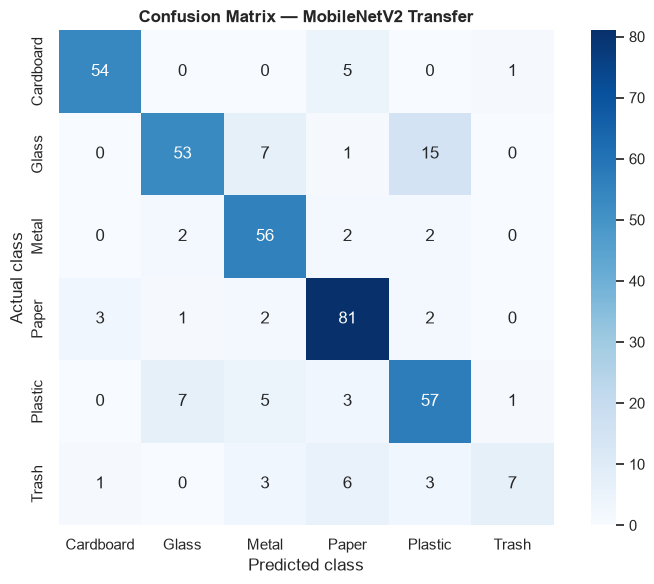

In [20]:
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", square=True,
    xticklabels=[name.capitalize() for name in class_names],
    yticklabels=[name.capitalize() for name in class_names],
)
plt.title(f"Confusion Matrix — {best_model_name}", weight="bold")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.tight_layout()
plt.show()

## 20. Classification Report

Precision measures how often a predicted class is correct, recall measures how many actual examples of a class are found, and F1-score balances the two. Per-class metrics are more informative than accuracy alone when classes have different sizes.

In [21]:
report_dict = classification_report(
    y_true, y_pred, labels=range(NUM_CLASSES), target_names=class_names,
    output_dict=True, zero_division=0
)
report_df = pd.DataFrame(report_dict).transpose()
display(report_df.round(4))

per_class_f1 = report_df.loc[class_names, "f1-score"]
print(f"Highest F1-score class: {per_class_f1.idxmax()} ({per_class_f1.max():.4f})")
print(f"Lowest F1-score class: {per_class_f1.idxmin()} ({per_class_f1.min():.4f})")
print("Use these computed values—not assumptions—to describe the easiest and hardest categories.")

,precision,recall,f1-score,support
cardboard,0.9310,0.9000,0.9153,60.0000
glass,0.8413,0.6974,0.7626,76.0000
metal,0.7671,0.9032,0.8296,62.0000
paper,0.8265,0.9101,0.8663,89.0000
plastic,0.7215,0.7808,0.7500,73.0000
trash,0.7778,0.3500,0.4828,20.0000
accuracy,0.8105,0.8105,0.8105,0.8105
macro avg,0.8109,0.7569,0.7678,380.0000
weighted avg,0.8135,0.8105,0.8048,380.0000


Highest F1-score class: cardboard (0.9153)
Lowest F1-score class: trash (0.4828)
Use these computed values—not assumptions—to describe the easiest and hardest categories.


## 21. Sample Predictions

The following cell displays random images from the untouched test set with their actual label, predicted label, and prediction confidence. These examples provide a qualitative check alongside the numerical metrics.

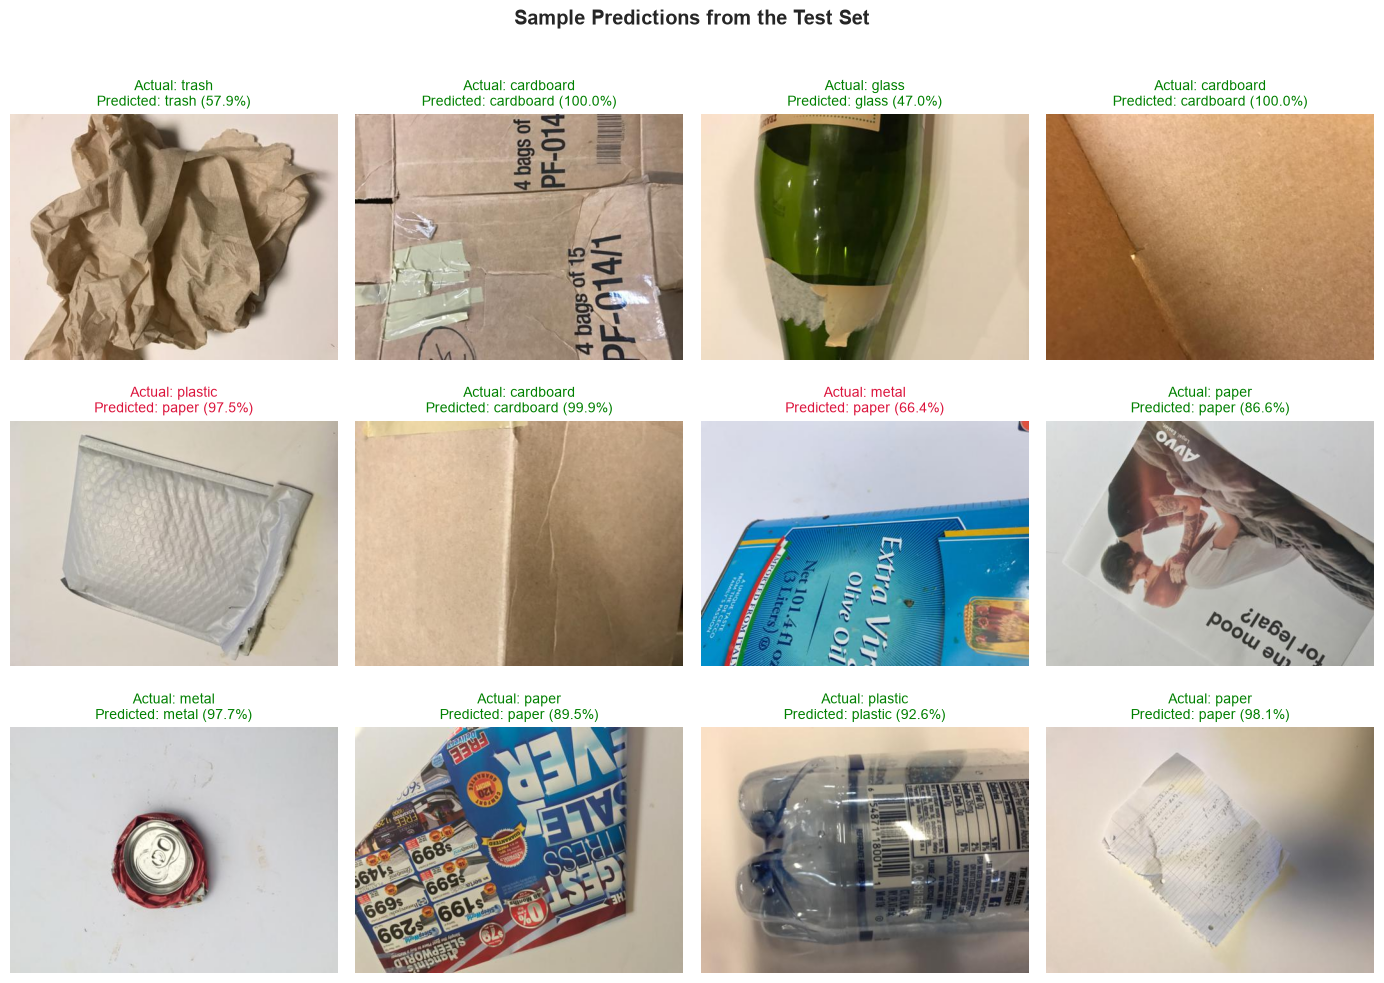

In [22]:
n_examples = min(12, len(test_df))
example_indices = test_df.sample(n=n_examples, random_state=SEED).index.to_list()
example_df = test_df.loc[example_indices].reset_index(drop=True)
example_ds = make_dataset(example_df)
example_probabilities = best_model.predict(example_ds, verbose=0)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, (_, row), probs in zip(axes.flat, example_df.iterrows(), example_probabilities):
    with Image.open(row["filepath"]) as image:
        ax.imshow(image.convert("RGB"))
    predicted_index = int(np.argmax(probs))
    predicted_class = index_to_class[predicted_index]
    confidence = float(np.max(probs))
    actual_class = row["class_name"]
    color = "green" if predicted_class == actual_class else "crimson"
    ax.set_title(
        f"Actual: {actual_class}\nPredicted: {predicted_class} ({confidence:.1%})",
        color=color, fontsize=10
    )
    ax.axis("off")

for ax in axes.flat[n_examples:]:
    ax.axis("off")
plt.suptitle("Sample Predictions from the Test Set", y=1.01, weight="bold")
plt.tight_layout()
plt.show()

## 22. Prediction Function

Use this function after training to classify a new image. It loads the saved final model and class mapping, applies the same resize and normalization used during training, and returns the predicted class with confidence.

In [23]:
def predict_waste(image_path, model_path=None, mapping_path=None):
    """Predict one image using the saved model and return class plus confidence."""
    image_path = Path(image_path)
    model_path = Path(model_path) if model_path else MODEL_DIR / "best_waste_classifier.keras"
    mapping_path = Path(mapping_path) if mapping_path else MODEL_DIR / "class_mapping.json"

    if not image_path.is_file():
        raise FileNotFoundError(f"Image not found: {image_path}")
    if not model_path.is_file():
        raise FileNotFoundError(
            f"Saved model not found: {model_path}. Run training and saving cells first, "
            "or copy a trained .keras model into the models folder."
        )
    if not mapping_path.is_file():
        raise FileNotFoundError(f"Class mapping not found: {mapping_path}")

    model = keras.models.load_model(model_path)
    with open(mapping_path, "r", encoding="utf-8") as file:
        saved_mapping = json.load(file)
    saved_index_to_class = {int(index): name for name, index in saved_mapping.items()}

    image_bytes = tf.io.read_file(str(image_path))
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE, antialias=True)
    image = tf.cast(image, tf.float32) / 255.0

    probabilities = model.predict(tf.expand_dims(image, axis=0), verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))
    return {
        "predicted_class": saved_index_to_class[predicted_index],
        "confidence": float(probabilities[predicted_index]),
    }

# Example after the final model has been saved:
# print(predict_waste("sample_images/my_waste_photo.jpg"))


## 23. Final Results

Run this cell after all training and evaluation cells. It produces a concise, evidence-based summary for the final report. No text values below are fixed; they come from the downloaded files and the current experiment.

In [24]:
print("FINAL RESULTS SUMMARY")
print(f"Dataset images: {len(manifest)}")
print(f"Number of classes: {NUM_CLASSES}")
print(f"Classes: {', '.join(class_names)}")
print(f"Selected architecture: {best_model_name}")
print(f"Model parameters: {best_model.count_params():,}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Weighted precision: {precision:.4f}")
print(f"Weighted recall: {recall:.4f}")
print(f"Weighted F1-score: {f1:.4f}")
print(f"Saved model: {FINAL_MODEL_PATH}")

FINAL RESULTS SUMMARY
Dataset images: 2527
Number of classes: 6
Classes: cardboard, glass, metal, paper, plastic, trash
Selected architecture: MobileNetV2 Transfer
Model parameters: 2,265,670
Test accuracy: 0.8105
Weighted precision: 0.8135
Weighted recall: 0.8105
Weighted F1-score: 0.8048
Saved model: c:\Persona Drive\waste_material_recognition_project\models\best_waste_classifier.keras


## 24. Conclusion

Write the conclusion **after running the notebook**. State that the project developed a TensorFlow/Keras waste-image classifier, identify the three architectures compared, and name the selected model based on the validation criterion. Insert the computed test metrics from the Final Results Summary.

Discuss real-world usefulness cautiously: TrashNet was collected in controlled conditions with a white background, so performance may drop for cluttered bins, poor lighting, occlusion, mixed materials, or categories not present in the dataset.

## 25. Future Scope

Possible future improvements include collecting more diverse real-world images, addressing minority classes with additional data or class-aware methods, fine-tuning the selected transfer-learning model with a validation-controlled experiment, detecting multiple items in one image, and deploying the model in a mobile or embedded smart-bin application.